# Edad biológica: del riesgo a una edad

¿A qué edad tiene una persona típica de su mismo sexo el mismo riesgo de morir en 10 años?

**Método.** El riesgo a 10 años se pasa a la escala del logaritmo del riesgo acumulado, que en la población crece casi en línea recta con la edad. Una curva por sexo describe a la persona típica, y la edad biológica es la edad de esa curva con el mismo riesgo. Dos formas de definir a la persona típica:

- **A. Referencia común:** la que da el baseline (Cox con edad y sexo). Es lo que hace PhenoAge.
- **Final. Referencia de cada nivel:** la mediana de lo que da el propio modelo del nivel a la gente de cada edad y sexo, con una curva de segundo grado.

Listones fijados antes de ver los resultados:

- **Calibración por edad:** en cada grupo de edad y sexo, la diferencia entre edad biológica y edad real debería quedar dentro de **±1 año**.
- **Salto del RDW:** si el RDW de todos sube lo que subió con el cambio de analizador, la mediana del cambio de la edad biológica tiene que ser **de 1 año o menos**. Si lo supera, el RDW se ajusta o se quita.

Sin pesos muestrales. Todo dentro de train: **el test no se toca**.

Notebook de trabajo: importa de `src/`. Tiempo aproximado, si se ejecuta entero: unos 15 minutos.

In [1]:
# Imports
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter

sys.path.insert(0, str(Path.cwd().parent))
from src.config.model_sets import BASE, BASELINE, EXTRAS, QUESTIONNAIRE
from src.config.paths import GOLD_TABLE
from src.models.s1_split import split_data
from src.models.s2_preprocessing import build_preprocessor
from src.models.s3_algorithms import build_pipeline, survival_target
from src.models.s4_biological_age import biological_age, fit_reference, reference_risk
from src.models.s5_evaluation import evaluate_level, risk_at_horizon
from src.utils.features import age_groups

C:\Data\1_MisCosas\Evolve\TFM\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Datos

Mismo reparto que en los niveles: 80/20 con 5 bloques dentro de train. `BASE` ya no lleva el RDW (sección 2); aquí se vuelve a añadir para medirlo.

In [2]:
LEVELS = {
    "level_1": BASE,
    "level_2": BASE + EXTRAS,
    "level_3": BASE + QUESTIONNAIRE,
    "level_4": BASE + EXTRAS + QUESTIONNAIRE,
}
WITH_RDW = {name: columns + ["rdw"] for name, columns in LEVELS.items()}
GAP_LIMIT = 1  # years, calibration by age group and sex
RDW_LIMIT = 1  # years, median change from the analyser jump

gold = pd.read_parquet(GOLD_TABLE)
train, test, folds = split_data(gold)

          people       deaths      
part        test train   test train
cycle                              
1999_2000    829  3316    212   846
2001_2002    925  3697    188   750
2003_2004    877  3511    165   661
2005_2006    874  3497    120   479
2007_2008   1043  4170    136   544
2009_2010   1120  4479     99   396
2011_2012    993  3968     70   278
2013_2014   1061  4248     51   206
2015_2016   1011  4043     31   122
2017_2018    966  3867     14    57
train: 38796 people, 4339 deaths
test:  9699 people, 1086 deaths
folds: [7760, 7759, 7759, 7759, 7759] people in each validation part


## 2. Salto del RDW

### 2.1. Cuánto mueve la edad

La mediana del RDW sube con el cambio de analizador de 2013-2014. Se mide esa subida en los datos y se suma al RDW de todas las personas de train. Luego se compara la edad biológica antes y después, con el Cox de cada nivel (con RDW) ajustado con todo train y su referencia. Describe el modelo, no mide su acierto.

In [3]:
recent = train["cycle"] >= "2013_2014"
rdw_jump = train.loc[recent, "rdw"].median() - train.loc[~recent, "rdw"].median()
print("RDW median before 2013:", train.loc[~recent, "rdw"].median(), "| from 2013:", train.loc[recent, "rdw"].median(), "| jump:", round(rdw_jump, 2))

RDW median before 2013: 12.5 | from 2013: 13.5 | jump: 1.0


In [4]:
def rdw_effect(columns):
    pipeline = build_pipeline("cox", columns).fit(train, survival_target(train))
    risk = risk_at_horizon(pipeline, train)
    reference = fit_reference(risk, train)
    shifted = risk_at_horizon(pipeline, train.assign(rdw=train["rdw"] + rdw_jump))
    change = biological_age(shifted, train["sex"], reference) - biological_age(risk, train["sex"], reference)
    return pd.Series(change, index=train.index)

rdw_changes = pd.DataFrame({name: rdw_effect(columns) for name, columns in WITH_RDW.items()})
rdw_summary = rdw_changes.describe(percentiles=[0.05, 0.5, 0.95]).T[["5%", "50%", "95%", "max"]].round(2)
rdw_summary["within_limit"] = rdw_summary["50%"].abs() <= RDW_LIMIT
rdw_summary

,5%,50%,95%,max,within_limit
level_1,2.16,2.84,3.50,3.92,False
level_2,1.74,2.33,3.04,3.41,False
level_3,1.76,2.18,2.51,2.77,False
level_4,1.43,1.84,2.27,2.56,False


### 2.2. Cuánto cuesta quitarlo

Cox de cada nivel con y sin RDW, con validación cruzada y los mismos bloques. `same_age_cost`: cuánto baja el C-index misma edad al quitarlo.

In [5]:
results = {name: evaluate_level(columns, train, folds, models=["cox"]) for name, columns in {"baseline": BASELINE, **LEVELS}.items()}
with_rdw = {name: evaluate_level(columns, train, folds, models=["cox"]) for name, columns in WITH_RDW.items()}

rdw_cost = pd.DataFrame({
    "c_index_with_rdw": [with_rdw[name][0].loc["cox", "c_index"] for name in LEVELS],
    "c_index": [results[name][0].loc["cox", "c_index"] for name in LEVELS],
    "same_age_with_rdw": [with_rdw[name][0].loc["cox", "c_index_same_age"] for name in LEVELS],
    "same_age": [results[name][0].loc["cox", "c_index_same_age"] for name in LEVELS],
}, index=list(LEVELS))
rdw_cost["same_age_cost"] = rdw_cost["same_age_with_rdw"] - rdw_cost["same_age"]
rdw_cost.round(4)

,c_index_with_rdw,c_index,same_age_with_rdw,same_age,same_age_cost
level_1,0.8476,0.8409,0.7034,0.6850,0.0184
level_2,0.8587,0.8548,0.7310,0.7204,0.0106
level_3,0.8554,0.8516,0.7249,0.7155,0.0094
level_4,0.8637,0.8614,0.7444,0.7387,0.0057


Sin RDW, frente al baseline: lo que sigue aportando la analítica.

In [6]:
summary = pd.concat({name: level_summary.iloc[0] for name, (level_summary, _) in results.items()}, axis=1).T
summary[["c_index", "c_index_same_age", "c_index_fit", "calibration_gap", "worst_underestimate"]].round(4)

,c_index,c_index_same_age,c_index_fit,calibration_gap,worst_underestimate
baseline,0.8159,0.5983,0.8159,0.0046,0.0082
level_1,0.8409,0.6850,0.8415,0.0024,0.0078
level_2,0.8548,0.7204,0.8557,0.0049,0.0102
level_3,0.8516,0.7155,0.8524,0.0041,0.0068
level_4,0.8614,0.7387,0.8624,0.0054,0.0197


### 2.3. Pesos del nivel 1 sin RDW

Cox simple ajustado con todo train, sin validación: describe el modelo, no mide su acierto. Al quitar una variable de la serie roja, las otras dos pueden cambiar de fuerza; aquí se ve si alguna cambia entre efecto claro y no claro.

- **`hazard_ratio`:** por cuánto se multiplica el riesgo al subir la variable una desviación estándar, a igualdad de las demás.
- **`clear`:** el intervalo del 95 % no incluye el 1.

In [7]:
def cox_weights(columns):
    features = build_preprocessor(columns).fit_transform(train)
    fitted = CoxPHFitter().fit(features.join(train[["follow_up_months", "death"]]), "follow_up_months", "death").summary
    weights = pd.DataFrame({"hazard_ratio": fitted["exp(coef)"], "low": fitted["exp(coef) lower 95%"], "high": fitted["exp(coef) upper 95%"]})
    weights["clear"] = (weights["low"] > 1) | (weights["high"] < 1)
    return weights

weights = pd.concat({"with_rdw": cox_weights(WITH_RDW["level_1"]), "without_rdw": cox_weights(LEVELS["level_1"])}, axis=1)
weights.round(3)

with_rdw                      without_rdw                    
             hazard_ratio    low   high clear hazard_ratio    low   high clear
covariate                                                                     
age                 3.440  3.282  3.607  True        3.575  3.411  3.746  True
bmi                 0.952  0.911  0.994  True        0.946  0.905  0.988  True
hemoglobin          1.357  1.271  1.448  True        1.106  1.039  1.176  True
erythrocytes        0.673  0.634  0.715  True        0.772  0.727  0.819  True
mchc                0.877  0.842  0.914  True        0.840  0.806  0.876  True
neutrophils         1.166  1.126  1.207  True        1.200  1.159  1.243  True
lymphocytes         0.918  0.890  0.948  True        0.907  0.879  0.937  True
monocytes           1.057  1.021  1.094  True        1.097  1.061  1.136  True
glucose             1.180  1.150  1.210  True        1.196  1.166  1.227  True
creatinine          1.110  1.082  1.139  True        1.157  1.127  1.187  True
urea                0.914  0.882  0.947  True        0.894  0.863  0.927  True
uric_acid           1.129  1.093  1.166  True        1.124  1.088  1.162  True
hdl                 0.954  0.923  0.987  True        0.958  0.927  0.991  True
ast                 1.318  1.256  1.382  True        1.374  1.310  1.442  True
alt                 0.735  0.695  0.778  True        0.713  0.673  0.754  True
sodium              0.945  0.919  0.971  True        0.937  0.912  0.964  True
potassium           1.076  1.047  1.106  True        1.077  1.047  1.107  True
rdw                 1.316  1.276  1.356  True          NaN    NaN    NaN   NaN
sex_male            1.374  1.269  1.487  True        1.412  1.305  1.529  True
bmi_squared         1.048  1.029  1.067  True        1.063  1.045  1.082  True

In [8]:
changed = weights.dropna()
print("Variables that change between clear and not clear:", changed.index[changed[("with_rdw", "clear")] != changed[("without_rdw", "clear")]].tolist())

Variables that change between clear and not clear: []


## 3. Las dos referencias

Con los modelos ya sin RDW. Cada persona recibe el riesgo de un modelo entrenado sin ella (sección 2.2), y ese riesgo se traduce a edad.

Riesgo a 10 años de la persona típica de cada edad y sexo, según la referencia A y la final de cada nivel.

In [9]:
common = fit_reference(results["baseline"][1]["cox"]["risk"], train)
references = {
    "A": {name: common for name in LEVELS},
    "final": {name: fit_reference(results[name][1]["cox"]["risk"], train) for name in LEVELS},
}
ages = np.arange(20, 80, 10)
pd.DataFrame({
    (option, name, sex): reference_risk(ages, [sex] * len(ages), reference)
    for option, by_level in references.items() for name, reference in by_level.items() for sex in ["female", "male"]
    if option == "final" or name == "level_1"
}, index=ages).T.round(4)

20      30      40      50      60      70
A     level_1 female  0.0042  0.0095  0.0215  0.0485  0.1072  0.2281
              male    0.0065  0.0148  0.0333  0.0743  0.1613  0.3302
final level_1 female  0.0050  0.0098  0.0199  0.0418  0.0899  0.1944
              male    0.0066  0.0130  0.0270  0.0593  0.1352  0.3071
      level_2 female  0.0046  0.0087  0.0175  0.0371  0.0818  0.1841
              male    0.0060  0.0117  0.0243  0.0534  0.1226  0.2829
      level_3 female  0.0039  0.0081  0.0176  0.0387  0.0862  0.1907
              male    0.0047  0.0105  0.0241  0.0561  0.1311  0.2968
      level_4 female  0.0038  0.0078  0.0164  0.0358  0.0808  0.1839
              male    0.0048  0.0102  0.0224  0.0513  0.1205  0.2800

Años de ventaja de las mujeres en la referencia A: a igual edad, un hombre tiene el riesgo de una mujer de tantos años más.

In [10]:
print("Years of difference between sexes:", round(float(biological_age(reference_risk(50, "male", common), "female", common) - 50), 1))

Years of difference between sexes: 5.3


## 4. Calibración por edad y sexo

`gap` = edad biológica − edad real. Cerca de 0, la persona típica de cada grupo sale con su edad; positiva, el modelo envejece a ese grupo; negativa, lo rejuvenece.

La referencia final se centra en la mediana, así que la mediana de cada grupo debería quedar cerca de 0 y la media algo por encima, por la cola de personas muy enfermas.

In [11]:
gaps = {
    option: pd.DataFrame({name: biological_age(results[name][1]["cox"]["risk"], train["sex"], by_level[name]) - train["age"] for name in LEVELS})
    for option, by_level in references.items()
}
groups = [age_groups(train), train["sex"]]
median_gap = pd.concat({option: table.groupby(groups, observed=True).median() for option, table in gaps.items()}, axis=1).round(2)
median_gap

A                           final                        
             level_1 level_2 level_3 level_4 level_1 level_2 level_3 level_4
age   sex                                                                   
18-29 female    1.60    0.53   -1.23   -1.39   -0.17   -0.08   -0.08    0.00
      male     -0.34   -1.46   -3.89   -3.75    0.04    0.07    0.12    0.17
30-39 female   -0.22   -2.03   -2.21   -3.17    0.04   -0.32   -0.03   -0.37
      male     -2.36   -3.79   -4.26   -5.08   -0.25   -0.38   -0.14   -0.34
40-49 female   -0.69   -2.31   -1.99   -3.10    0.80    0.65    0.68    0.47
      male     -2.74   -3.95   -4.16   -4.92    0.02    0.10   -0.37   -0.06
50-59 female   -2.58   -3.52   -3.18   -3.67   -0.55   -0.12   -0.37    0.04
      male     -2.48   -3.68   -2.96   -4.16    0.21    0.31    0.26    0.15
60-69 female   -2.86   -3.45   -3.20   -3.65   -0.60   -0.16   -0.51   -0.24
      male     -1.73   -2.85   -2.21   -3.11    0.10    0.25    0.05    0.17
70-79 female   -1.44   -2.44   -1.75   -2.45    0.54    0.04    0.44    0.06
      male     -0.55   -1.83   -1.00   -1.93   -0.15   -0.34   -0.04   -0.21

In [12]:
mean_gap = pd.concat({option: table.groupby(groups, observed=True).mean() for option, table in gaps.items()}, axis=1).round(2)
mean_gap

A                           final                        
             level_1 level_2 level_3 level_4 level_1 level_2 level_3 level_4
age   sex                                                                   
18-29 female    1.82    0.72   -0.46   -0.85    0.06    0.10    0.71    0.46
      male     -0.13   -1.06   -3.10   -3.28    0.14    0.39    0.87    0.63
30-39 female    0.26   -1.56   -1.04   -2.37    0.52    0.03    1.11    0.38
      male     -1.98   -3.20   -3.46   -4.21    0.01    0.00    0.57    0.43
40-49 female   -0.20   -1.65   -0.99   -2.10    1.21    1.19    1.62    1.33
      male     -2.24   -3.18   -3.16   -3.86    0.41    0.70    0.56    0.78
50-59 female   -1.90   -2.53   -1.96   -2.41    0.06    0.73    0.76    1.13
      male     -1.74   -2.52   -2.03   -2.71    0.78    1.19    1.02    1.34
60-69 female   -2.03   -2.63   -2.11   -2.54    0.14    0.47    0.46    0.64
      male     -0.98   -1.67   -1.08   -1.63    0.70    1.12    1.01    1.31
70-79 female   -0.62   -1.44   -0.83   -1.43    1.27    0.86    1.25    0.87
      male      0.05   -0.96   -0.33   -1.03    0.27    0.34    0.55    0.45

In [13]:
print("Groups outside +/-", GAP_LIMIT, "year:")
pd.DataFrame({"median": (median_gap.abs() > GAP_LIMIT).sum(), "mean": (mean_gap.abs() > GAP_LIMIT).sum()}).unstack(0)

Groups outside +/- 1 year:


median       mean      
             A final    A final
level_1      8     0    6     2
level_2     11     0   10     3
level_3     11     0    8     5
level_4     12     0   11     4

## 5. Dispersión con la referencia final

Cuánto se separa la edad biológica de la real. Un modelo que no aporta nada daría 0 a todos; uno que aporta, separa a la gente. Las colas son las personas a las que el resultado más avisa o más tranquiliza.

In [14]:
gaps["final"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T.round(2)

,count,mean,std,min,5%,25%,50%,75%,95%,max
level_1,38796.0,0.43,5.98,-30.03,-8.52,-3.54,0.0,3.88,10.75,42.18
level_2,38796.0,0.57,7.13,-31.47,-10.00,-4.10,0.0,4.54,13.01,49.77
level_3,38796.0,0.87,7.13,-26.41,-9.33,-4.26,0.0,5.39,13.66,52.27
level_4,38796.0,0.80,7.84,-23.59,-10.55,-4.70,0.0,5.48,14.71,55.88


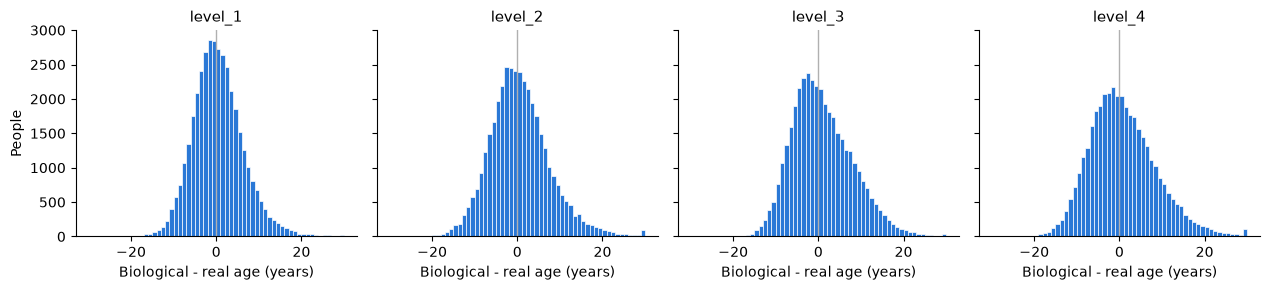

In [15]:
figure, axes = plt.subplots(1, len(LEVELS), figsize=(3.2 * len(LEVELS), 3.0), sharex=True, sharey=True)
bins = np.arange(-30, 31, 1)
for axis, name in zip(axes, LEVELS):
    axis.hist(gaps["final"][name].clip(-30, 30), bins=bins, color="#2a78d6", edgecolor="white", linewidth=0.5)
    axis.axvline(0, color="#b0b0b0", linewidth=1)
    axis.set_title(name, fontsize=11)
    axis.set_xlabel("Biological - real age (years)")
    axis.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("People")
figure.tight_layout()

## 6. Conclusión

**Edad biológica: la edad a la que la persona típica de tu mismo sexo, según el modelo de tu nivel, tiene tu riesgo a 10 años. Y el RDW sale del modelo.** Las cifras son de validación cruzada dentro de train; el test sigue sin tocar.

### Qué se hizo y por qué

**1. Medir el salto del RDW**

El salto medido en train es de 1,0 punto (mediana de 12,5 antes de 2013 y 13,5 después). Sumado a todos, sube la edad biológica una mediana de **2,8 años en el nivel 1** y **1,8 en el nivel 4**, y el límite era 1 año. En la app sería un sesgo de todo un laboratorio, invisible para el usuario, y un ajuste propio no resolvería la escala desconocida de los analizadores españoles. Por eso sale.

| Cox simple | Misma edad con RDW | Sin RDW | Coste |
|---|---|---|---|
| Nivel 1 | 0,703 | 0,685 | 0,018 |
| Nivel 2 | 0,731 | 0,720 | 0,011 |
| Nivel 3 | 0,725 | 0,716 | 0,009 |
| Nivel 4 | 0,744 | 0,739 | 0,006 |

Sin RDW, todos los niveles siguen muy por encima del baseline (0,598 misma edad) y en el mismo orden. En el nivel 1 ninguna variable cambia entre efecto claro y no claro; la hemoglobina pierde fuerza (de 1,36 a 1,11), sin cambiar de signo.

**2. Elegir la referencia**

- **A, común (la del baseline):** la persona típica sale más joven que su edad, hasta 5 años en hombres de 30-49 del nivel 4, y peor cuantas más variables tiene el modelo. Un modelo con más variables separa más a la gente, y la media en la escala logarítmica del riesgo cae por debajo del riesgo de la persona media. Es infraestimar, el error peor.
- **Primera prueba, recta media de cada nivel:** casi lo arreglaba, pero la persona típica (la mediana) seguía 1-2 años por debajo, por la cola de personas muy enfermas, y una recta no seguía bien los extremos de edad.
- **Final, curva mediana de segundo grado de cada nivel:** mediana de cada grupo de edad y sexo dentro de ±1 año en todos los niveles (máximo 0,8). La media queda algo por encima (hasta 1,6 años): ante la duda, la app tira hacia mayor, que es el lado prudente.

| Grupos fuera de ±1 año (de 12) | Nivel 1 | Nivel 2 | Nivel 3 | Nivel 4 |
|---|---|---|---|---|
| A, mediana | 8 | 11 | 11 | 12 |
| Final, mediana | 0 | 0 | 0 | 0 |
| Final, media | 2 | 3 | 5 | 4 |

**3. Dispersión**

Con la referencia final, la mitad de la gente queda entre unos 4 años por debajo y 4-5 por encima de su edad, y el 90 % entre unos −10 y +14. La cola alta es larga (hasta +56 años): son las personas muy enfermas. Cuanto más completo es el nivel, más separa a la gente.

### Resultado final

| | Decisión |
|---|---|
| Referencia | La de cada nivel: mediana de su propio riesgo por edad y sexo, curva de segundo grado, ajustada con train |
| Fuera de 18-79 | La curva sigue en línea recta: riesgos extremos dan edades fuera del rango |
| RDW | Fuera del modelo; Base queda con 18 variables |

### Pendiente

- Cómo mostrar las edades fuera de 18-79 y la cola larga: con la pantalla de resultado.
- Los niveles 2 a 4 sin RDW no se han vuelto a comparar con bootstrap; el nivel 4 sigue claramente por delante del 2 (0,739 frente a 0,720 misma edad).
- PhenoAge, contra el mejor modelo de cada nivel.